# 03 Exploratory data analysis

> **Synthetic data, sampled simulation.** 768 simulated runs compared with 19,708 scheduled runs (3.9%). Not IRCTC or Indian Railways network-wide data. No forecasts. Associations are not causes.

**Structure:** A booking demand, B passenger behaviour, C operations, D financial, E temporal. Months are compared on per-run and capacity-normalised measures, because exactly 32 runs are simulated every month. Full written summary: `reports/phase5_eda_summary.md`.

In [1]:
# Setup: find the project root, make python/src importable, load shared helpers (the data is only READ)
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data" / "processed" / "cleaned").exists())
sys.path.insert(0, str(ROOT / "python" / "src"))
import pandas as pd, numpy as np
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from analytics import data_loader as dl, validation, cleaning, kpi, eda, SYNTHETIC_NOTE
from analytics import statistics as stats
print(SYNTHETIC_NOTE)
%matplotlib inline
from IPython.display import Image, display

Synthetic data, sampled simulation (768 simulated runs of 19,708 scheduled). Not IRCTC or Indian Railways network-wide data; no forecasts.


In [2]:
ds = dl.load_dataset()
clean = cleaning.run_cleaning(ds.tables); facts = clean.facts
monthly = kpi.monthly_kpis(facts)
pf, bf, ef, cf, rf = (facts[k] for k in ("passenger_fact", "booking_fact", "event_fact", "class_run_fact", "run_fact"))
E = eda.run_eda(facts, monthly)
VIS = ROOT / 'visuals' / 'phase5_python'

## A. Booking demand

,journey_month,total_bookings,total_passengers,simulated_runs,bookings_per_run,passengers_per_run,bookings_growth,bookings_per_run_growth
0,2024-09,5944,12159,32,185.7500,379.9688,NaN,NaN
1,2024-10,7727,15448,32,241.4688,482.7500,0.3000,0.3000
2,2024-11,7934,16023,32,247.9375,500.7188,0.0268,0.0268
3,2024-12,7457,14941,32,233.0312,466.9062,-0.0601,-0.0601
4,2025-01,7939,16225,32,248.0938,507.0312,0.0646,0.0646
5,2025-02,7165,14255,32,223.9062,445.4688,-0.0975,-0.0975
6,2025-03,9243,18628,32,288.8438,582.1250,0.2900,0.2900
7,2025-04,9150,18515,32,285.9375,578.5938,-0.0101,-0.0101
8,2025-05,10856,21782,32,339.2500,680.6875,0.1864,0.1864
9,2025-06,8073,16270,32,252.2812,508.4375,-0.2564,-0.2564


,day_type,runs,bookings,passengers,booked,seats,passengers_per_run,bookings_per_run,occupancy
0,Weekday (Mon-Fri),588,156609,315251,"243,425.0000",332642,536.1412,266.3418,0.7318
1,Weekend (Sat-Sun),180,44573,89949,"69,920.5000",93742,499.7167,247.6278,0.7459


,booking_status,bookings,share
0,Confirmed,146020,0.7258
1,RAC,11169,0.0555
2,Waitlisted,12749,0.0634
3,Cancelled,26619,0.1323
4,Mixed,4625,0.0230


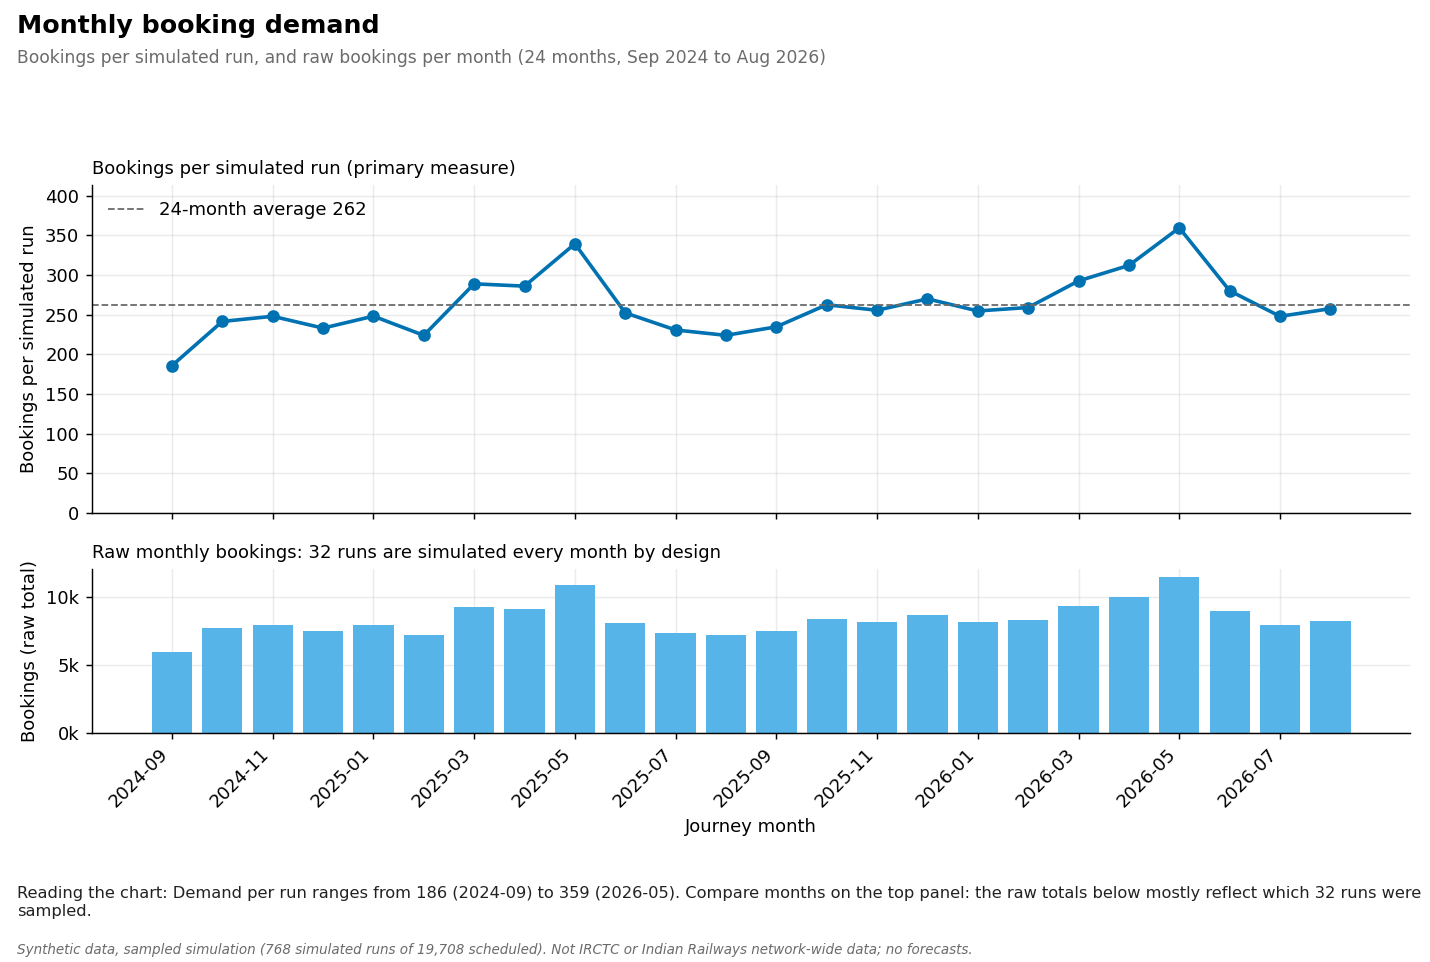

In [3]:
display(E['monthly_demand'])
display(E['weekend_vs_weekday'])
display(E['booking_status_mix'])
display(Image(filename=str(VIS / '01_monthly_demand_trend.png')))

**Reading it:** compare months on the per-run line; the raw bars only reflect that 32 runs are simulated each month.

## B. Passenger behaviour

,status,initial,final,initial_share,final_share
0,Confirmed,340054,301671,0.8392,0.7445
1,RAC,28270,23349,0.0698,0.0576
2,Waitlisted,36876,24200,0.0910,0.0597
3,Cancelled,0,55980,0.0000,0.1382


,travel_class,passengers,cancellation_rate,initial_wl_share,wl_clearance_rate
0,1A,641,0.0811,0.0515,0.1818
1,2A,23137,0.1070,0.0666,0.1284
2,3A,122748,0.1293,0.0972,0.1977
3,SL,154096,0.1461,0.0964,0.2037
4,CC,4239,0.1246,0.0101,0.2558
5,2S,100339,0.1449,0.0844,0.1756


,item,bookings
0,bookings with at least one cancelled passenger,30562
1,of which every passenger cancelled (fully canc...,26619
2,of which partially cancelled,3943
3,bookings with 2+ passengers,107448
4,mixed-status bookings,4625


,multi,bookings,mixed,mixed_share
0,1,93734,0,0.0000
1,2,56059,2270,0.0405
2,3,21904,965,0.0441
3,4,19631,905,0.0461
4,5,4012,197,0.0491
5,6,5842,288,0.0493


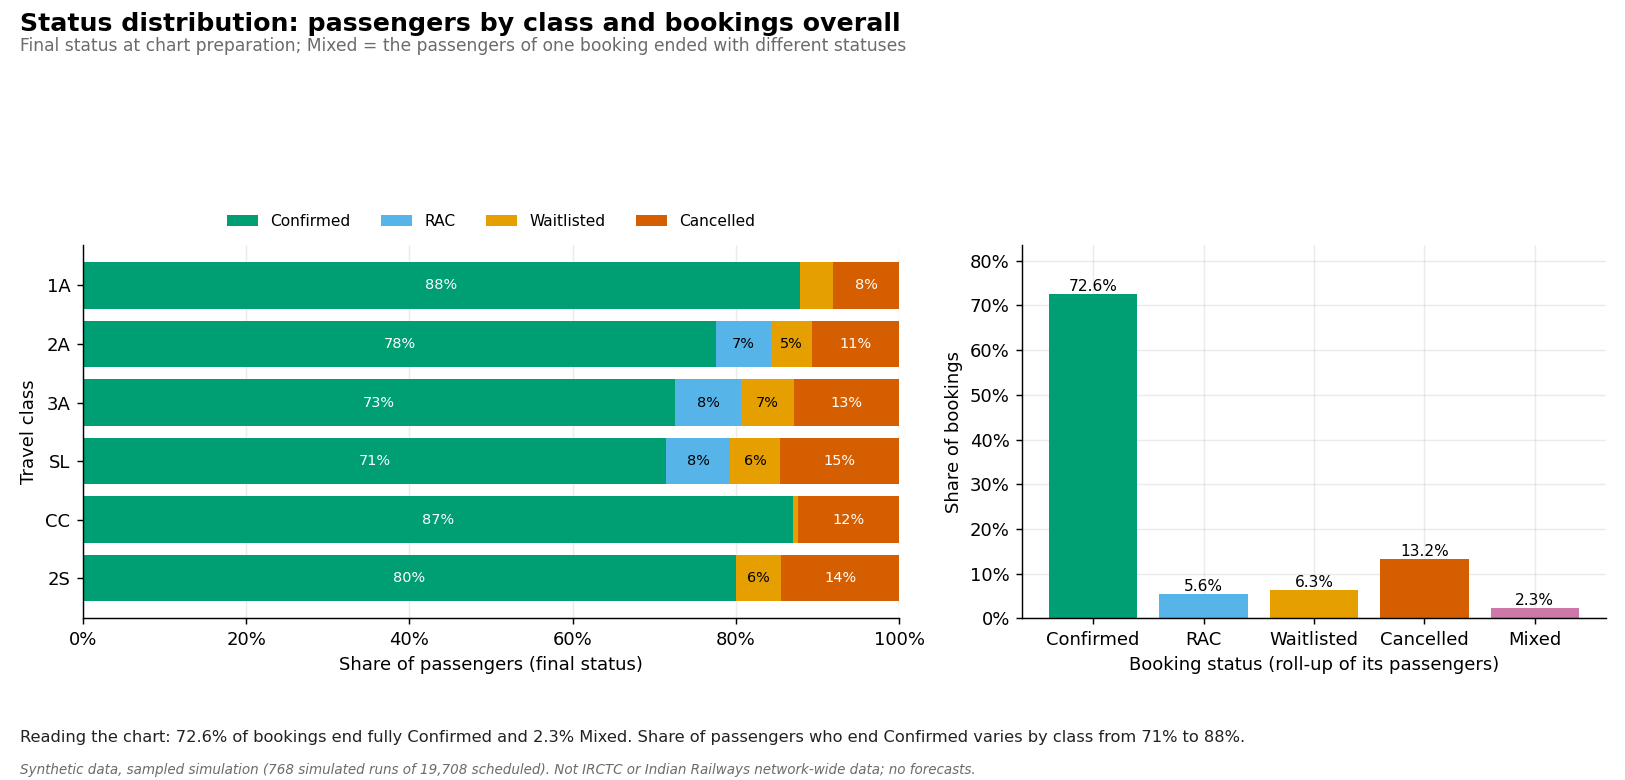

In [4]:
display(E['passenger_status_mix'])
display(E['by_class'][['travel_class', 'passengers', 'cancellation_rate', 'initial_wl_share', 'wl_clearance_rate']])
display(E['cancellation_shape'])
display(E['mixed_by_party_size'])
display(Image(filename=str(VIS / '10_status_distribution.png')))

## C. Operations: trains, routes, classes, occupancy

,travel_class,class_runs,seats,passengers,occupancy,confirmed_occupancy,waitlist_pressure,demand_per_seat,occ_ci_low,occ_ci_high
0,1A,29,768,641,0.7331,0.7331,0.0339,0.8346,0.6567,0.7991
1,2A,351,25760,23137,0.7269,0.6965,0.0448,0.8982,0.7015,0.7503
2,3A,734,122368,122748,0.7681,0.7281,0.0653,1.0031,0.7516,0.7842
3,SL,720,154368,154096,0.7524,0.7136,0.0611,0.9982,0.7361,0.7683
4,CC,34,7020,4239,0.5254,0.5254,0.0033,0.6038,0.4577,0.5930
5,2S,417,116100,100339,0.6910,0.6910,0.0480,0.8642,0.6678,0.7131


,measure,value
0,class-runs,"2,285.0000"
1,mean occupancy,0.7360
2,median occupancy,0.7609
3,5th percentile,0.3261
4,25th percentile,0.5417
5,75th percentile,0.9861
6,95th percentile,1.0000
7,share of class-runs below 50% occupancy,0.2004
8,share of class-runs at or above 95%,0.3116
9,share of class-runs with any uncleared waitlist,0.2573


,train_number,train_name,runs,passengers_per_run,occupancy,occ_ci_low,occ_ci_high,otp
14,S1015,Lucknow–Mumbai Express 2,15,"1,063.6000",0.9764,0.9594,0.9904,0.8000
50,S1051,Vijayawada–Patna Express,17,780.5882,0.9415,0.8996,0.9702,0.6471
45,S1046,Kolkata–Hyderabad Superfast 2,15,680.9333,0.9407,0.9188,0.9625,0.9333
44,S1045,Hyderabad–Kolkata Superfast 2,18,817.5556,0.9403,0.9091,0.9677,0.6667
13,S1014,Mumbai–Lucknow Premium 1,11,420.5455,0.9379,0.8974,0.9717,0.7000


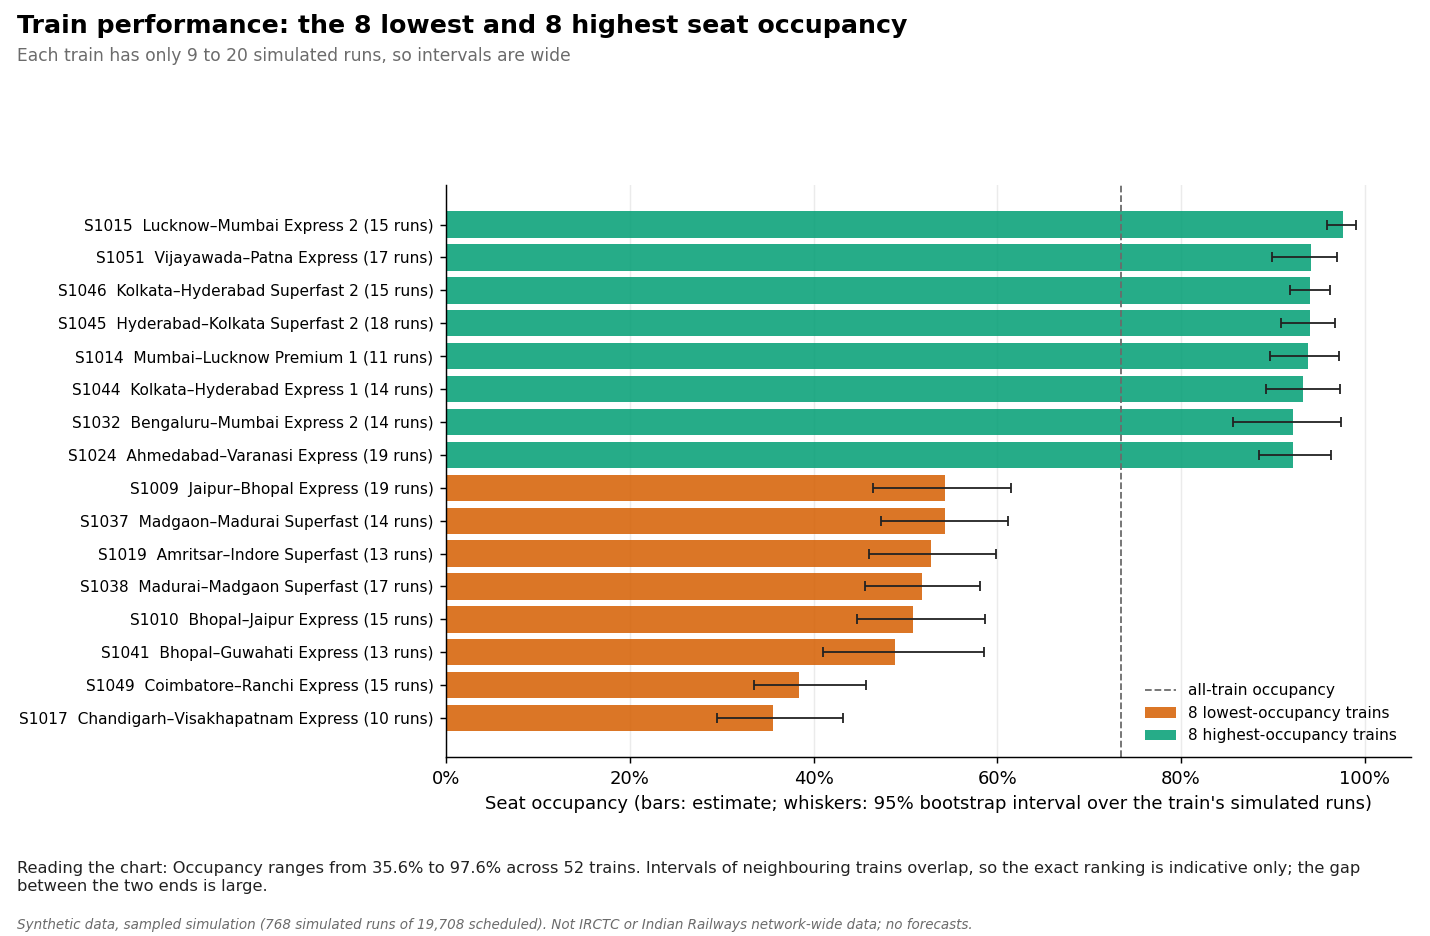

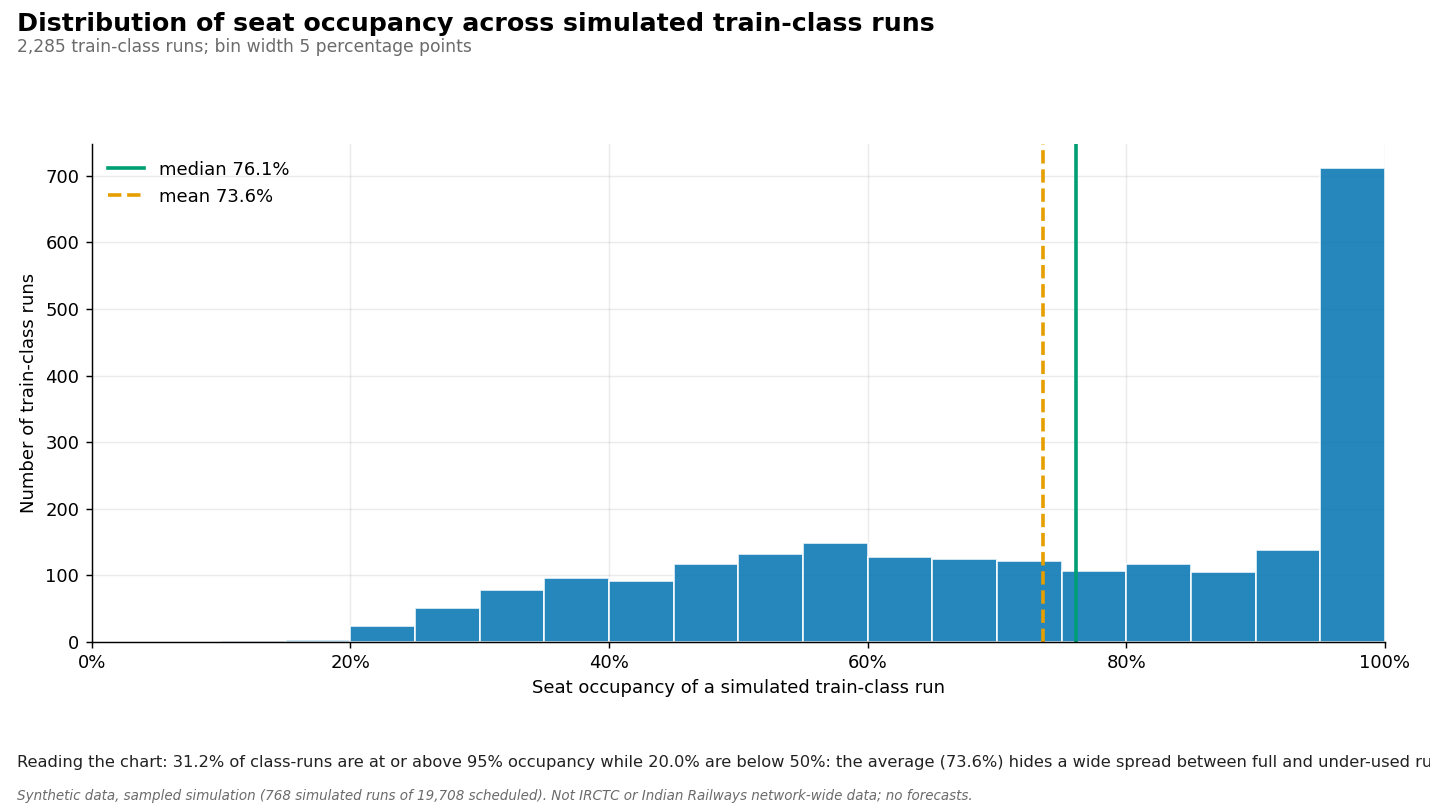

In [5]:
display(E['class_level'])
display(E['occupancy_distribution'])
display(E['train_level'].sort_values('occupancy', ascending=False).head(5)[['train_number', 'train_name', 'runs', 'passengers_per_run', 'occupancy', 'occ_ci_low', 'occ_ci_high', 'otp']])
display(Image(filename=str(VIS / '07_train_performance.png')))
display(Image(filename=str(VIS / '14_occupancy_distribution.png')))

Each train has only 9 to 20 simulated runs, so the intervals are wide and rankings are indicative.

## D. Financial analysis (INR; booking value is not revenue)

,journey_month,gross_value,refund_total,net_value,gross_per_run,refund_share_of_gross
0,2024-09,"18,403,297.0000","2,358,383.7500","16,044,913.2500","575,103.0312",0.1282
1,2024-10,"24,124,782.0000","3,594,946.2500","20,529,835.7500","753,899.4375",0.1490
2,2024-11,"23,920,040.0000","4,190,534.2500","19,729,505.7500","747,501.2500",0.1752
3,2024-12,"23,795,348.0000","3,449,323.0000","20,346,025.0000","743,604.6250",0.1450
4,2025-01,"23,019,795.0000","3,424,008.7500","19,595,786.2500","719,368.5938",0.1487
5,2025-02,"21,171,056.0000","3,110,455.5000","18,060,600.5000","661,595.5000",0.1469
6,2025-03,"26,983,278.0000","4,896,893.5000","22,086,384.5000","843,227.4375",0.1815
7,2025-04,"28,114,523.0000","5,103,113.5000","23,011,409.5000","878,578.8438",0.1815


,cancellation_type,events,passengers,original,charge,refund,charge_share
0,Passenger,30661,55980,"80,815,181.0000","8,930,744.0000","71,884,437.0000",0.1105
1,System,13262,24200,"35,925,090.0000","726,000.0000","35,199,090.0000",0.0202


,percentile,fare_per_passenger_inr
0,p1,288.0000
1,p5,435.0000
2,p25,753.0000
3,p50,"1,053.0000"
4,p75,"2,211.0000"
5,p95,"3,694.0000"
6,p99,"4,482.0000"


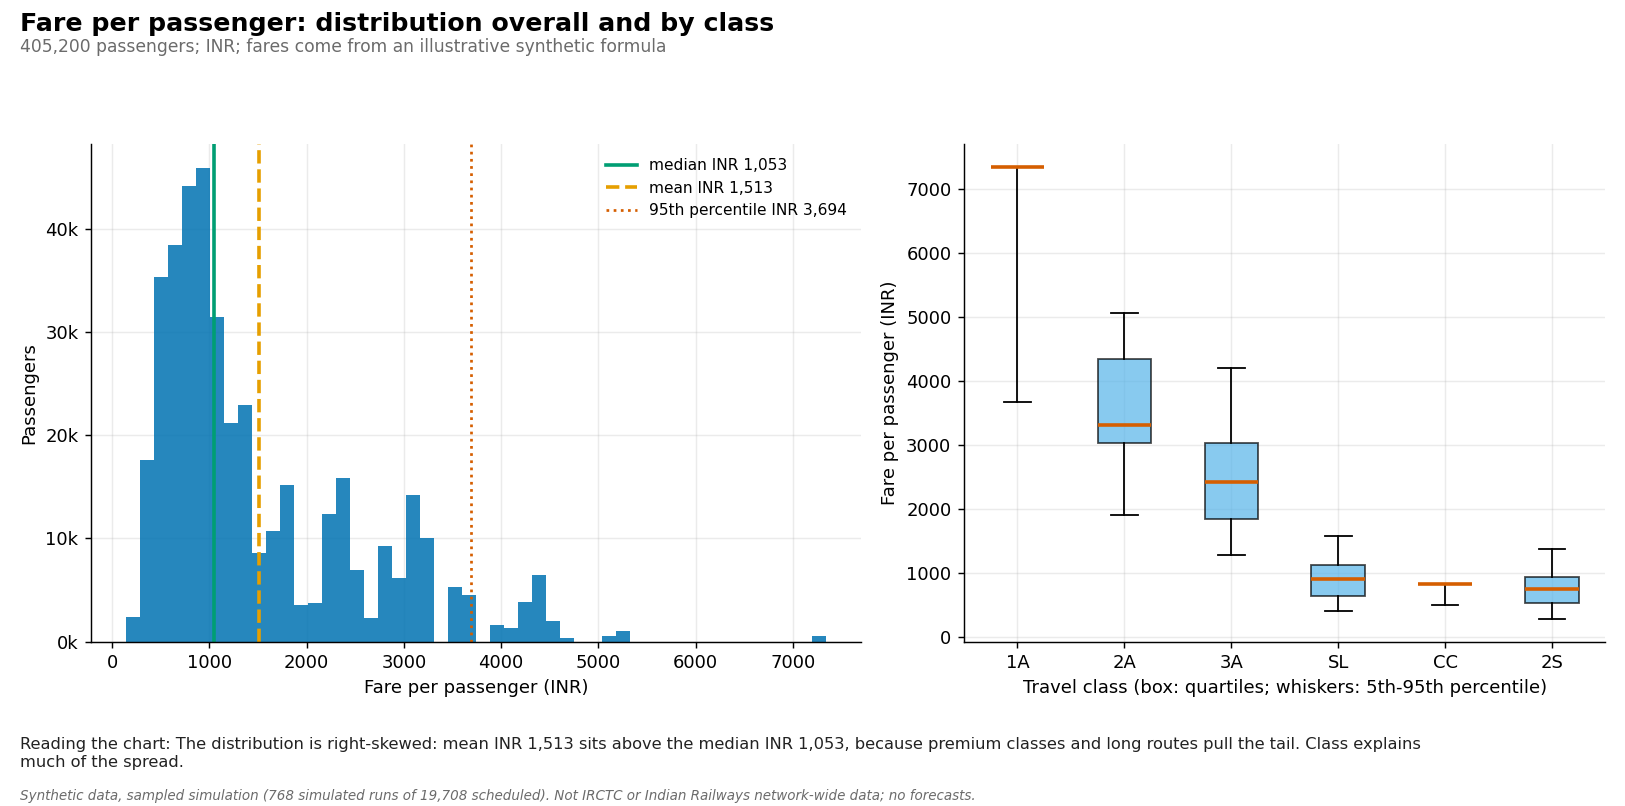

In [6]:
display(E['monthly_value'][['journey_month', 'gross_value', 'refund_total', 'net_value', 'gross_per_run', 'refund_share_of_gross']].head(8))
display(E['refund_by_type'])
display(E['fare_distribution'])
display(Image(filename=str(VIS / '11_fare_distribution.png')))

## E. Temporal analysis

,journey_month,total_bookings,bookings_growth,bookings_per_run,bookings_per_run_growth,occupancy,passenger_cancellation_rate
0,2024-09,5944,NaN,185.7500,NaN,0.5839,0.1323
1,2024-10,7727,0.3000,241.4688,0.3000,0.6835,0.1382
2,2024-11,7934,0.0268,247.9375,0.0268,0.7017,0.1353
3,2024-12,7457,-0.0601,233.0312,-0.0601,0.6619,0.1293
4,2025-01,7939,0.0646,248.0938,0.0646,0.6891,0.1375
5,2025-02,7165,-0.0975,223.9062,-0.0975,0.6511,0.1317
6,2025-03,9243,0.2900,288.8438,0.2900,0.7936,0.1350
7,2025-04,9150,-0.0101,285.9375,-0.0101,0.7757,0.1378


,season,runs,passengers,passengers_per_run,occupancy,runs_with_delay,otp,avg_delay
0,Monsoon,256,123723,483.2930,0.6997,249,0.7309,22.5663
1,Post-Monsoon,128,64950,507.4219,0.7138,124,0.7903,11.8306
2,Summer,192,120725,628.7760,0.8287,185,0.7838,13.4270
3,Winter,192,95802,498.9688,0.7015,187,0.7059,24.5989


,period,runs,passengers,passengers_per_run,occupancy
0,Other days,607,302352,498.1087,0.7066
1,Peak travel period,161,102848,638.8075,0.8423


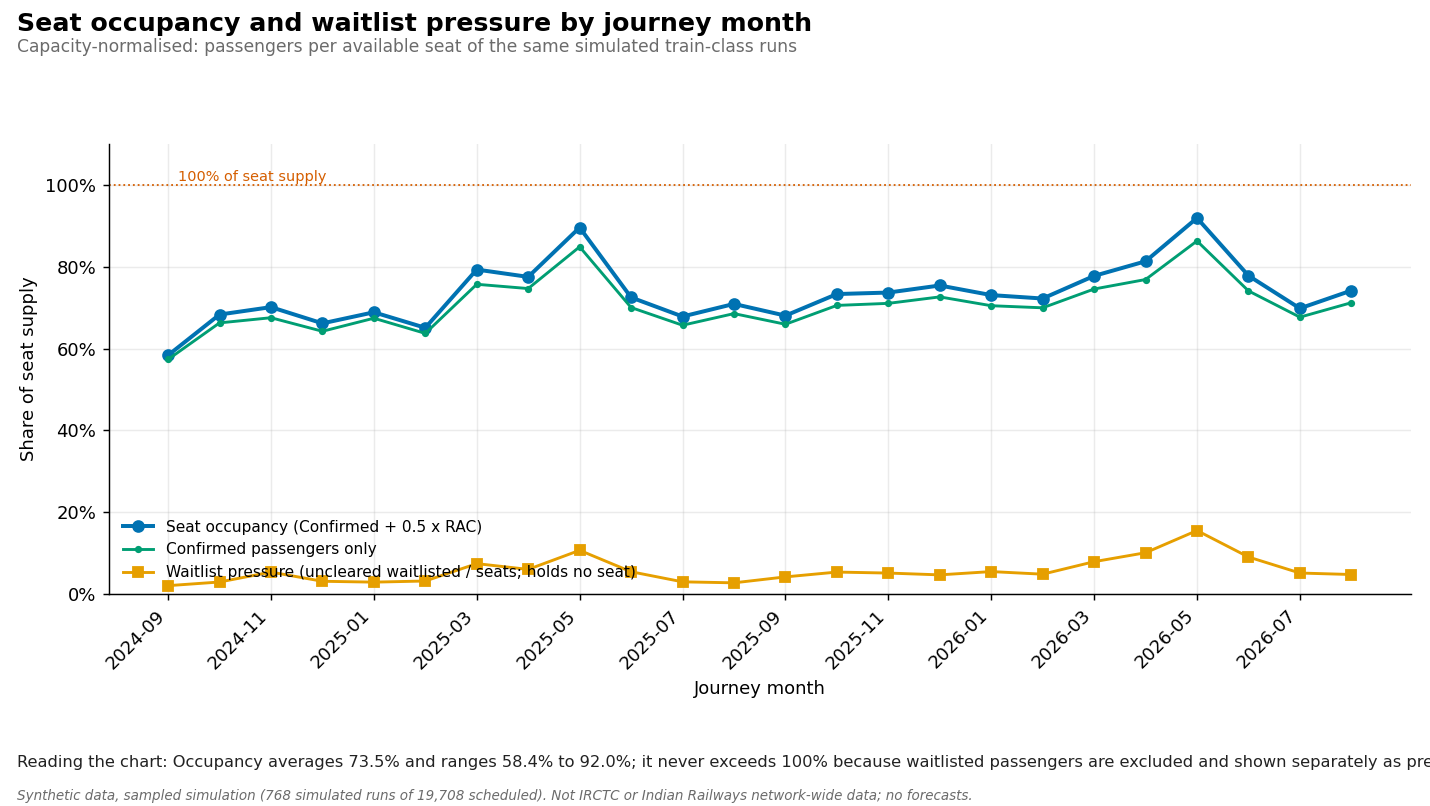

In [7]:
display(E['mom_changes'].head(8))
display(E['season_level'])
display(E['peak_level'])
display(Image(filename=str(VIS / '05_occupancy_trend.png')))

Only two years are simulated, so each calendar month is observed twice: seasonal patterns describe these two years, not a stable cycle. The generator builds in seasonal and holiday demand (assumption A-20), so finding it is a check of the method.